In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score


In [ ]:

from google.colab import files
import pandas as pd

uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())


Saving placement_predict_50k Dataset.csv to placement_predict_50k Dataset (1).csv
Dataset loaded successfully!
Dataset shape: (50000, 32)
Columns: ['StudentID', 'Gender', 'City', 'CollegeTier', 'Stream', 'Specialisation', 'Hostel', 'HistoryOfBacklogs', 'SGPA_Sem1', 'SGPA_Sem2', 'SGPA_Sem3', 'SGPA_Sem4', 'SGPA_Sem5', 'SGPA_Sem6', 'SGPA_Sem7', 'SGPA_Sem8', 'CGPA', 'AttendancePercent', 'Internships', 'Projects', 'Workshops', 'Certifications', 'Publications', 'AptitudeTestScore', 'SoftSkillsRating', 'CodingTestScore', 'MockInterviewScore', 'ExtraCurricular', 'CGPA_Tier', 'PlacementStatus', 'IsAnomaly', 'Salary Package']


,StudentID,Gender,City,CollegeTier,Stream,Specialisation,Hostel,HistoryOfBacklogs,SGPA_Sem1,SGPA_Sem2,...,Publications,AptitudeTestScore,SoftSkillsRating,CodingTestScore,MockInterviewScore,ExtraCurricular,CGPA_Tier,PlacementStatus,IsAnomaly,Salary Package
0,1,Male,Ahmedabad,Tier2,ECE,Networking,No,No,6.02,6.54,...,0,66.7,2.2,49.4,47.8,0,Low,0,0,0.00
1,2,Female,Mumbai,Tier2,ECE,DataScience,Yes,Yes,5.84,5.12,...,0,48.2,2.4,26.7,25.8,0,Low,0,0,0.00
2,3,Male,Kolkata,Tier2,IT,DataScience,Yes,No,4.91,5.29,...,0,73.8,2.8,67.7,41.5,0,Low,1,0,3.89
3,4,Male,Jaipur,Tier1,CS,AI,No,No,7.67,8.03,...,0,69.8,2.7,66.9,48.0,0,Mid,1,0,8.37
4,5,Male,Pune,Tier2,IT,DataScience,Yes,No,8.14,8.97,...,1,73.1,2.1,71.7,61.7,1,High,1,0,18.99


In [ ]:

X = df.drop(columns=["PlacementStatus", "CGPA_Tier"])
y = df["PlacementStatus"]

print("Features and target selected successfully!")
print("Features shape:", X.shape)
print("Target shape:", y.shape)


Features and target selected successfully!
Features shape: (50000, 30)
Target shape: (50000,)


In [ ]:

from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)


Training data: (40000, 30)
Validation data: (10000, 30)


In [ ]:

import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

numeric_cols = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X_train.select_dtypes(exclude=np.number).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_cols),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)

print("Preprocessing completed successfully!")
print("Training shape:", X_train_processed.shape)
print("Validation shape:", X_val_processed.shape)


Preprocessing completed successfully!
Training shape: (40000, 52)
Validation shape: (10000, 52)


In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

def compare_regularisation(X_train, y_train, X_val, y_val, C_values):
    results = []

    for C in C_values:
        models = {
            "Lasso": LogisticRegression(
                penalty="l1", solver="saga",
                C=C, max_iter=5000, random_state=42
            ),
            "Ridge": LogisticRegression(
                penalty="l2", solver="lbfgs",
                C=C, max_iter=5000
            ),
            "ElasticNet": LogisticRegression(
                penalty="elasticnet", solver="saga",
                l1_ratio=0.5, C=C,
                max_iter=5000, random_state=42
            )
        }

        row = {"C": C}

        for name, model in models.items():
            model.fit(X_train, y_train)
            predictions = model.predict(X_val)

            row[f"{name}_val_acc"] = accuracy_score(
                y_val, predictions
            )

            if name in ["Lasso", "Ridge"]:
                row[f"{name}_nonzero"] = np.count_nonzero(
                    np.abs(model.coef_) > 1e-6
                )

        results.append(row)

    return pd.DataFrame(results)


In [ ]:

C_values = [0.001, 0.01, 0.1, 1, 10, 100]

results_df = compare_regularisation(
    X_train_processed,
    y_train,
    X_val_processed,
    y_val,
    C_values
)

display(results_df.round(4))


,C,Lasso_val_acc,Lasso_nonzero,Ridge_val_acc,Ridge_nonzero,ElasticNet_val_acc
0,0.001,0.9906,8,0.9614,52,0.9811
1,0.010,0.9974,12,0.9926,52,0.9948
2,0.100,0.9969,18,0.9965,52,0.9968
3,1.000,0.9968,36,0.9968,52,0.9968
4,10.000,0.9968,51,0.9968,52,0.9968
5,100.000,0.9968,52,0.9968,52,0.9968


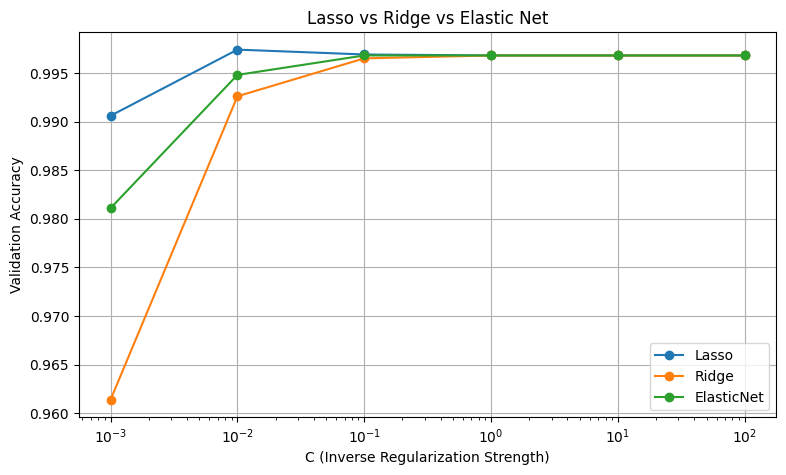

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

for model in ["Lasso", "Ridge", "ElasticNet"]:
    plt.plot(
        results_df["C"],
        results_df[f"{model}_val_acc"],
        marker="o",
        label=model
    )

plt.xscale("log")
plt.xlabel("C (Inverse Regularization Strength)")
plt.ylabel("Validation Accuracy")
plt.title("Lasso vs Ridge vs Elastic Net")
plt.legend()
plt.grid(True)
plt.show()


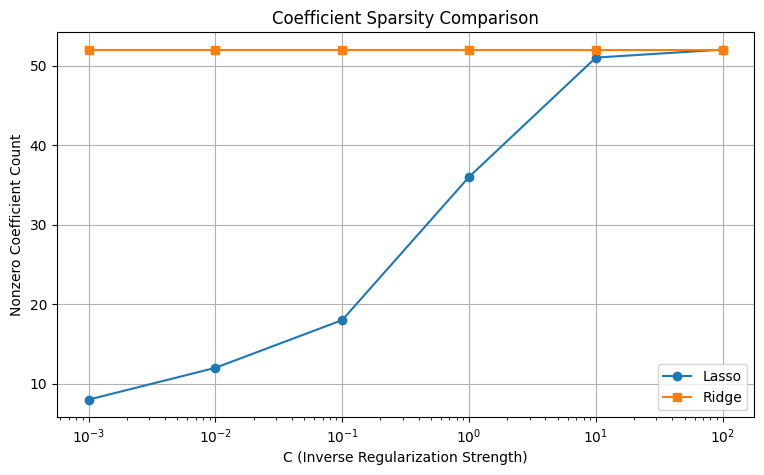

In [ ]:

plt.figure(figsize=(9, 5))

plt.plot(
    results_df["C"], results_df["Lasso_nonzero"],
    marker="o", label="Lasso"
)
plt.plot(
    results_df["C"], results_df["Ridge_nonzero"],
    marker="s", label="Ridge"
)

plt.xscale("log")
plt.xlabel("C (Inverse Regularization Strength)")
plt.ylabel("Nonzero Coefficient Count")
plt.title("Coefficient Sparsity Comparison")
plt.legend()
plt.grid(True)
plt.show()
